<a href="https://colab.research.google.com/github/hubertwojcik/deep_learning/blob/main/5_Fixed_vs_dynamic_learning_rate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [50]:
# import all necessary modules
import numpy as np
import matplotlib.pyplot as plt

import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

# Create the function and its derivative[link text](https://)

In [51]:
x = np.linspace(-2,2,2001)

# function (as a function)
def fx(x):
  return 3*x**2 - 3*x + 4

# derivative function
def deriv(x):
  return 6*x - 3

## G.D. using a fixed learning rate

In [52]:
local_min = np.random.choice(x,1)
init_value = local_min[:]

learning_rate = .01
training_epochs = 50

model_params_fixed = np.zeros((training_epochs,3))

for i in range(training_epochs):
  grad = deriv(local_min)

  local_learning_rate = learning_rate

  local_min = local_min - local_learning_rate*grad

  model_params_fixed[i, 0] = local_min[0]
  model_params_fixed[i, 1] = grad[0]
  model_params_fixed[i, 2] = local_learning_rate


## G.D. using a gradient-based learning rate

In [53]:
local_min = np.random.choice(x, 1)
init_value = local_min[:]

# learning parameters
learning_rate = .01
training_epochs = 50

# run through training and store all the results
model_params_grad = np.zeros((training_epochs,3))
for i in range(training_epochs):

  # compute gradient
  grad = deriv(local_min)

  # adapt the learning rate according to the gradient
  local_learning_rate = learning_rate*np.abs(grad)

  # update parameter according to g.d.
  local_min = local_min - local_learning_rate*grad

  # store the parameters
  model_params_grad[i,0] = local_min[0]
  model_params_grad[i,1] = grad[0]
  model_params_grad[i,2] = local_learning_rate[0]

## G.D. using a time-based learning rate

In [54]:
learning_rate = .1
local_min = init_value


model_params_time = np.zeros((training_epochs,3))
for i in range(training_epochs):
  grad = deriv(local_min)
  lr = learning_rate*(1-(i+1)/training_epochs)
  local_min = local_min - lr*grad
  model_params_time[i,0] = local_min[0]
  model_params_time[i,1] = grad[0]
  model_params_time[i,2] = lr

## Plot



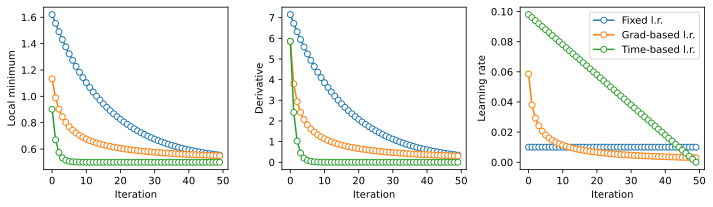

In [55]:
fig,ax = plt.subplots(1,3,figsize=(10,3))


for i in range(3):
  ax[i].plot(model_params_fixed[:,i],'o-',markerfacecolor='w')
  ax[i].plot(model_params_grad[:,i],'o-',markerfacecolor='w')
  ax[i].plot(model_params_time[:,i],'o-',markerfacecolor='w')
  ax[i].set_xlabel('Iteration')

ax[0].set_ylabel('Local minimum')
ax[1].set_ylabel('Derivative')
ax[2].set_ylabel('Learning rate')
ax[2].legend(['Fixed l.r.','Grad-based l.r.','Time-based l.r.'])

plt.tight_layout()
plt.show()